# FNEWS dataset EDA

**Research objective.** Verify the bounded paired Fakeddit dataset, its source labels, modality coverage, and known limitations.

All results are read from local FNEWS artifacts. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independently verified factuality labels. The held-out test partition is not opened by these notebooks except where a prior frozen metric is explicitly quoted.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## Dataset and provenance

Fakeddit is a Reddit-derived multimodal benchmark. The local research dataset contains only validated text-image pairs. Its binary source label is derived from a six-way taxonomy: raw `1` is source-true; raw `0` aggregates non-true categories. This makes it useful for controlled benchmarking but not a general factuality corpus.

In [2]:
splits={s:paired(s) for s in ['train','validate','test']}
summary=pd.DataFrame([{'split':s,'pairs':len(f),'raw_0_non_true':int((f.fake_news_label==0).sum()),'raw_1_true':int((f.fake_news_label==1).sum())} for s,f in splits.items()])
show_frame(summary)
print('Verified paired total:',sum(summary.pairs))
print('Processed dataset GiB:',sum(p.stat().st_size for p in DATA.rglob('*') if p.is_file())/1024**3)

,split,pairs,raw_0_non_true,raw_1_true
0,train,2353,1154,1199
1,validate,933,556,377
2,test,947,565,382


Verified paired total: 4233
Processed dataset GiB: 0.15799175016582012


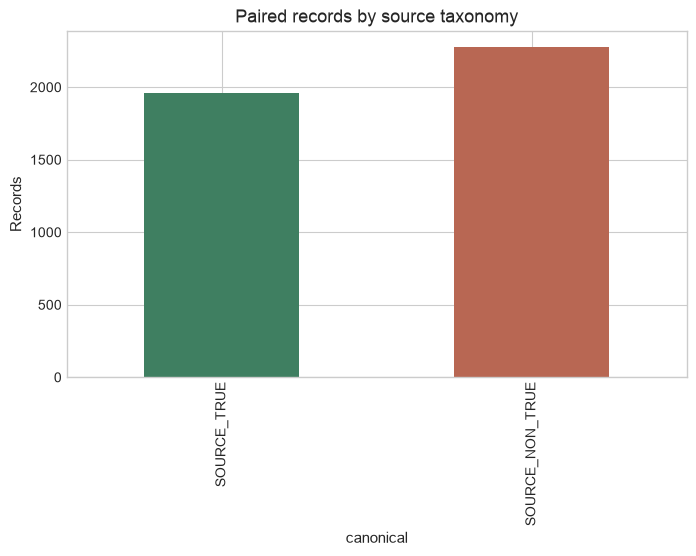

chars                                               words  \
                  count   mean    std  min   25%   50%   75%    max   count   
canonical                                                                     
SOURCE_NON_TRUE  2275.0  34.86  29.55  1.0  15.0  27.0  46.0  285.0  2275.0   
SOURCE_TRUE      1958.0  53.79  33.57  5.0  31.0  48.0  66.0  292.0  1958.0   

                                                        
                 mean   std  min  25%  50%   75%   max  
canonical                                               
SOURCE_NON_TRUE  6.26  5.33  1.0  2.0  5.0   8.0  54.0  
SOURCE_TRUE      9.49  5.88  1.0  6.0  8.0  11.0  50.0

In [3]:
all_pairs=pd.concat(splits.values(),ignore_index=True); all_pairs['canonical']=source_names(canonical_source_labels(all_pairs.fake_news_label))
ax=all_pairs.canonical.value_counts().reindex(['SOURCE_TRUE','SOURCE_NON_TRUE']).plot.bar(color=['#3f7f61','#b86753'],title='Paired records by source taxonomy');ax.set_ylabel('Records');plt.show()
all_pairs['chars']=all_pairs.text.str.len();all_pairs['words']=all_pairs.text.str.split().str.len();display(all_pairs.groupby('canonical')[['chars','words']].describe().round(2))

## Text EDA

TF-IDF uses the cleaned title text. The distributions below describe the actual paired dataset, not an inferred web-news distribution.

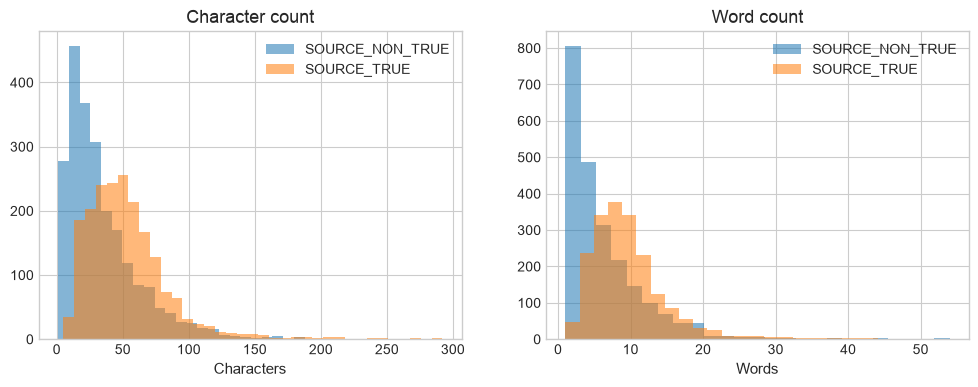

Duplicate-title members: 146


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4));
for label,group in all_pairs.groupby('canonical'):
    axes[0].hist(group.chars,bins=35,alpha=.55,label=label);axes[1].hist(group.words,bins=25,alpha=.55,label=label)
axes[0].set(title='Character count',xlabel='Characters');axes[1].set(title='Word count',xlabel='Words');[a.legend() for a in axes];plt.show()
print('Duplicate-title members:',int(all_pairs.duplicated('text',keep=False).sum()))

## Image and multimodal EDA

Images were decoded, bounded, and checked for cross-split duplicate risk during construction. The plot and gallery use only locally verified image files.

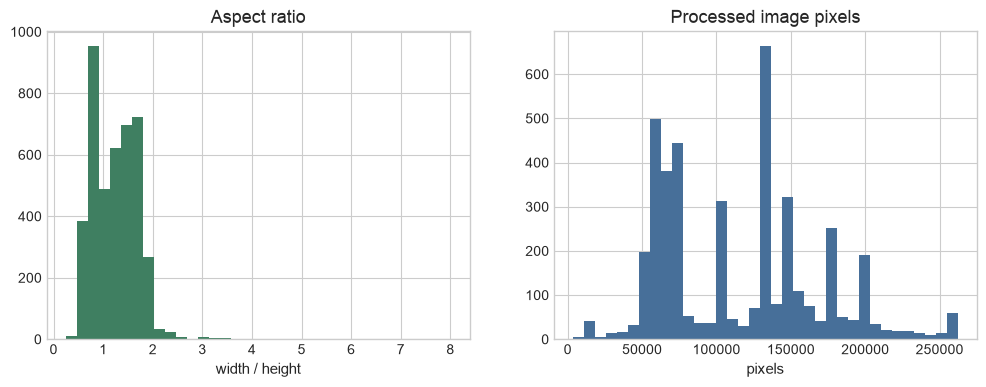

Missing text: 0 Missing image path: 0 Unique image hashes: 4204


In [5]:
all_pairs['aspect']=all_pairs.image_width/all_pairs.image_height;all_pairs['pixels']=all_pairs.image_width*all_pairs.image_height
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].hist(all_pairs.aspect,bins=35,color='#3f7f61');axes[0].set(title='Aspect ratio',xlabel='width / height');axes[1].hist(all_pairs.pixels,bins=35,color='#476f99');axes[1].set(title='Processed image pixels',xlabel='pixels');plt.show()
print('Missing text:',int(all_pairs.text.isna().sum()),'Missing image path:',int(all_pairs.image_path.isna().sum()),'Unique image hashes:',all_pairs.image_hash.nunique())

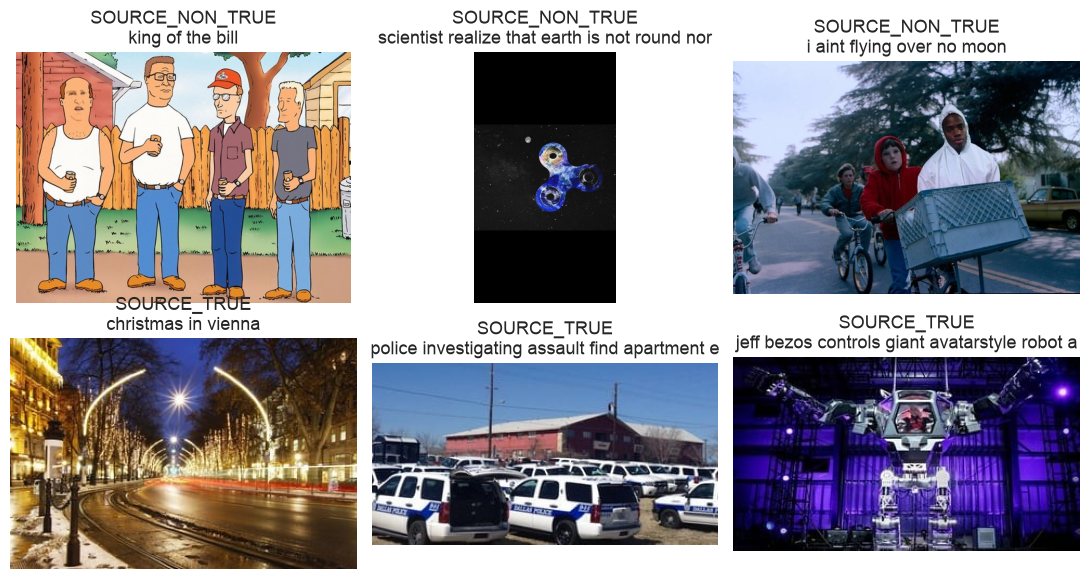

In [6]:
gallery=all_pairs.groupby('canonical',group_keys=False).sample(3,random_state=42);fig,axes=plt.subplots(2,3,figsize=(11,6));
for ax,(_,row) in zip(axes.flat,gallery.iterrows()):
    ax.imshow(Image.open(DATA/row.image_path).convert('RGB'));ax.set_title(row.canonical+'\n'+row.text[:45]);ax.axis('off')
plt.tight_layout();plt.show()

## Findings and limitations

The observed dataset has 4,233 verified pairs in preserved train/validation/test membership. Titles can be short or context-poor, source categories are heterogeneous, and text/image pairing does not independently prove claim truth. Recommended preprocessing: fit statistics on train only, preserve source labels, keep images RGB-decoded, and do not report live-news factuality accuracy from this benchmark.